# 1. Деректерді барлау талдауы (EDA): Stanford Dogs

Бұл ноутбукта жобаның деректерін зерттейміз: құрылымы, сапасы, кластардың таралуы және суреттердің сипаттамалары.
Деректерді ашу, тексеру, тазалау және бөлу `scripts/01_prepare_data.py` скриптінде жасалды, ал мұнда сол жұмыстың нәтижелерін талдаймыз.

**Мазмұны**
1. Деректерді жүктеу
2. Жетіспейтін мәндер және деректер сапасы
3. Бөлініс (train / val / test)
4. Кластардың таралуы
5. Сурет өлшемдері
6. Аннотация: ит кадрдың қанша бөлігін алады?
7. Түс және жарықтық
8. Мысалдар
9. Деректердегі белгі қателері
10. Қорытынды

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from src import plot_style, eda
from src.config import DATA_QUALITY_JSON
from src.data_utils import load_json

%matplotlib inline
plot_style.apply()
pd.set_option("display.max_columns", 30)

## 1. Деректерді жүктеу

**Дереккөз:** Stanford Dogs Dataset (Khosla et al., 2011), http://vision.stanford.edu/aditya86/ImageNetDogs/ .
Суреттер ImageNet-тен алынған. GeeksforGeeks мақаласындағы Kaggle «Dog Breed Identification» деректері осы жиынның бір бөлігі (тұқымдары бірдей).

Кестеде әр жол — бір сурет. Негізгі бағандар:
- `path`: файл жолы; `breed`: тұқым (**мақсатты айнымалы**); `label`: тұқым индексі (0–119);
- `split`: бөлік (train/val/test); `official_split`: ресми бөлінісі;
- `width`, `height`, `file_kb`, `fmt`, `mode`: суреттің сипаттамалары;
- `n_dogs`, `bbox_frac_max`: аннотациядан (суреттегі ит саны және ең үлкен иттің кадрдағы ауданы);
- `excluded`, `exclude_reason`: тазалау кезінде алынып тасталды ма және неге.

In [2]:
df = eda.load_all()
print("Өлшемі:", df.shape)
df.head()

Өлшемі: (20580, 25)


,path,orig_rel,synset,breed,label,official_split,split,excluded,exclude_reason,fixed,fmt,mode,width,height,file_kb,n_dogs,bbox_frac_max,bbox_frac_sum,mean_r,mean_g,mean_b,brightness,md5,dhash,abspath
0,data/raw/stanford_dogs/Images/n02085620-Chihua...,n02085620-Chihuahua/n02085620_5927.jpg,n02085620,Chihuahua,0,train,train,False,NaN,False,JPEG,RGB,360,300,13.3,1,0.541704,0.541704,91.45,89.50,78.17,86.37,1436fdd9328b02a62a8b70c22ffc8095,2b23f3f0f6366cd4,C:\Users\Lenovo\AppData\Local\Claude-Data\clau...
1,data/raw/stanford_dogs/Images/n02085620-Chihua...,n02085620-Chihuahua/n02085620_4441.jpg,n02085620,Chihuahua,0,train,train,False,NaN,False,JPEG,RGB,375,500,10.7,1,0.293328,0.293328,159.58,126.84,131.92,139.45,6a98da040d4f6f436feeb54bbecb08fa,f8f686ccc6c306f8,C:\Users\Lenovo\AppData\Local\Claude-Data\clau...
2,data/raw/stanford_dogs/Images/n02085620-Chihua...,n02085620-Chihuahua/n02085620_1502.jpg,n02085620,Chihuahua,0,train,train,False,NaN,False,JPEG,RGB,500,333,23.0,1,0.700937,0.700937,155.11,133.62,119.88,136.21,42c231fd588097cb73ab877237f53b14,aef818131b0b0e0d,C:\Users\Lenovo\AppData\Local\Claude-Data\clau...
3,data/raw/stanford_dogs/Images/n02085620-Chihua...,n02085620-Chihuahua/n02085620_1916.jpg,n02085620,Chihuahua,0,train,train,False,NaN,False,JPEG,RGB,500,495,47.0,1,0.705939,0.705939,118.32,108.72,93.37,106.81,d58d96b248968cebb9c26cdfd5836a41,ee6a289937665231,C:\Users\Lenovo\AppData\Local\Claude-Data\clau...
4,data/raw/stanford_dogs/Images/n02085620-Chihua...,n02085620-Chihuahua/n02085620_13151.jpg,n02085620,Chihuahua,0,train,train,False,NaN,False,JPEG,RGB,500,336,14.4,1,0.367333,0.367333,177.77,78.85,17.28,91.30,d0590e6b00379417b38164d06bf31f4d,e8e6e4e4cccccc9c,C:\Users\Lenovo\AppData\Local\Claude-Data\clau...


In [3]:
df[["width", "height", "file_kb", "n_dogs", "bbox_frac_max", "brightness"]].describe().round(2)

,width,height,file_kb,n_dogs,bbox_frac_max,brightness
count,20580.00,20580.00,20580.00,20580.00,20580.00,20580.00
mean,442.53,385.86,36.90,1.08,0.54,112.11
std,142.79,124.86,32.41,0.30,0.24,26.84
min,97.00,100.00,2.90,1.00,0.01,19.74
25%,361.00,333.00,22.80,1.00,0.35,94.49
50%,500.00,375.00,32.20,1.00,0.55,111.74
75%,500.00,453.00,43.90,1.00,0.75,128.75
max,3264.00,2562.00,1097.60,6.00,1.00,237.03


## 2. Жетіспейтін мәндер және деректер сапасы

In [4]:
missing = df.drop(columns=["exclude_reason"]).isna().sum()
print("Жетіспейтін мәндердің жалпы саны:", int(missing.sum()))
quality = load_json(DATA_QUALITY_JSON)
{k: v for k, v in quality.items() if k != "duplicate_examples"}

Жетіспейтін мәндердің жалпы саны: 0


{'total_images': 20580,
 'classes': 120,
 'corrupt_files': 0,
 'fixed_images': 1,
 'fixed_reasons': {'PNG/RGBA': 1},
 'near_duplicate_pairs': 130,
 'duplicate_clusters': 128,
 'label_conflict_clusters': 48,
 'excluded_by_reason': {'label_conflict': 57,
  'duplicate_of_test': 39,
  'duplicate_in_train': 34},
 'split_counts': {'train': 10070, 'test': 8580, 'val': 1800},
 'missing_annotation': 0}

In [5]:
df.groupby(["official_split", "exclude_reason"]).size().unstack(fill_value=0)

exclude_reason,duplicate_in_train,duplicate_of_test,label_conflict
official_split,,,
train,34,39,57


**Не таптық және не істедік?**
- **Жетіспейтін мәндер жоқ:** әр суреттің тұқымы, өлшемі және аннотациясы бар. Бұзылған (ашылмайтын) файл жоқ.
- **Қате формат:** 1 файлдың кеңейтімі `.jpg`, бірақ іші PNG (RGBA, мөлдір фонымен). Оны RGB JPEG-ке айналдырдық (`data/processed/fixed_images`).
- **Көшірмелер:** әр суреттің MD5 хэші мен dHash «саусақ ізі» есептелді. Хэмминг қашықтығы ≤ 2 және пропорциясы ұқсас 130 жуық көшірме жұбы (128 топ) табылды.
  - 39 train суреті **test-тегі суреттің көшірмесі** болды. Модель оларды оқуда көрсе, test-те «жатқа» білер еді (*data leakage*). Сондықтан олар train-нен алынды.
  - 34 сурет train-нің ішінде қайталанған: әр топтан біреуі ғана қалдырылды.
  - **48 топта бірдей сурет екі түрлі тұқыммен белгіленген** (белгі қайшылығы). Мұндай train суреттері (57) алынды, ал **test ресми күйінде қалдырылды** (басқа зерттеулермен салыстыруға болуы үшін).
- Нәтижесінде 20 580 суреттің 130-ы (0,6%) ғана алынды.

## 3. Бөлініс (train / val / test)

- **test** — ресми test бөлігі (8 580 сурет). Тек соңғы бағалауға қолданылады.
- **val** — ресми train-нен әр тұқым бойынша кездейсоқ 15 сурет (1 800). Гиперпараметрлерді және соңғы модельді таңдау осы бөлік бойынша жасалады.
- **train** — қалған суреттер (10 070). Модель осыларда оқиды.

In [6]:
kept = df[~df["excluded"]]
pd.DataFrame({"сурет саны": kept["split"].value_counts(),
              "үлесі": kept["split"].value_counts(normalize=True).round(3)})

,сурет саны,үлесі
split,,
train,10070,0.492
test,8580,0.420
val,1800,0.088


## 4. Кластардың таралуы

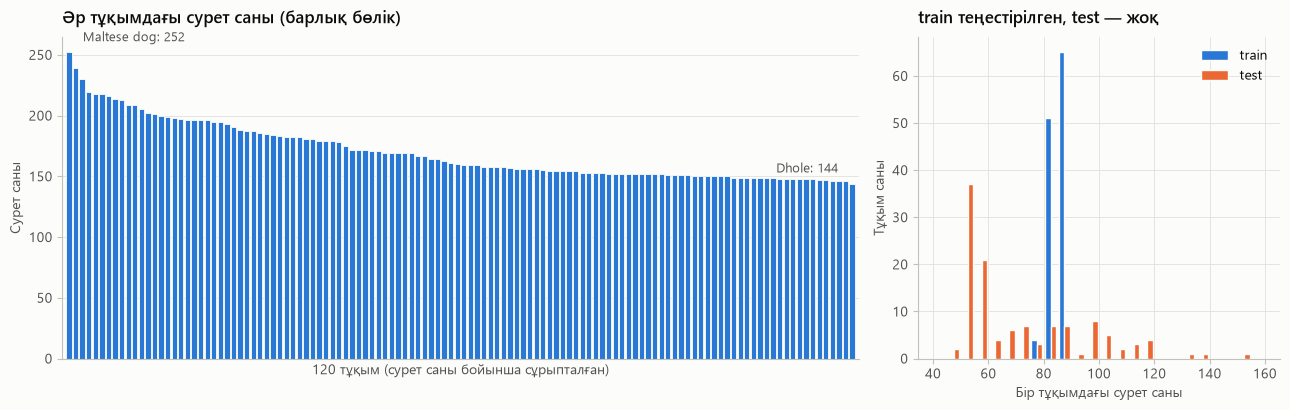

split,test,train,val
count,120.0,120.0,120.0
mean,71.5,83.9,15.0
std,23.2,1.7,0.0
min,48.0,77.0,15.0
25%,52.8,83.0,15.0
50%,59.5,85.0,15.0
75%,86.2,85.0,15.0
max,152.0,85.0,15.0


In [7]:
eda.fig_class_distribution(df, show=True)
per_split = kept.groupby(["breed", "split"]).size().unstack()
per_split.describe().round(1)

**Қорытынды:** барлық бөлікте бір тұқымға 144 (Dhole) мен 252 (Maltese dog) аралығында сурет келеді.
Ресми train бөлігі **теңестірілген** (әр тұқымда 100 сурет, валидация мен көшірмелерден кейін 77–85), сондықтан класс салмақтарын немесе SMOTE қолдану қажет емес.
Ал **test теңестірілмеген** (бір тұқымға 48–152 сурет). Сондықтан accuracy-мен қатар әр тұқымды тең ескеретін **macro F1** метрикасын да есептейміз.

## 5. Сурет өлшемдері

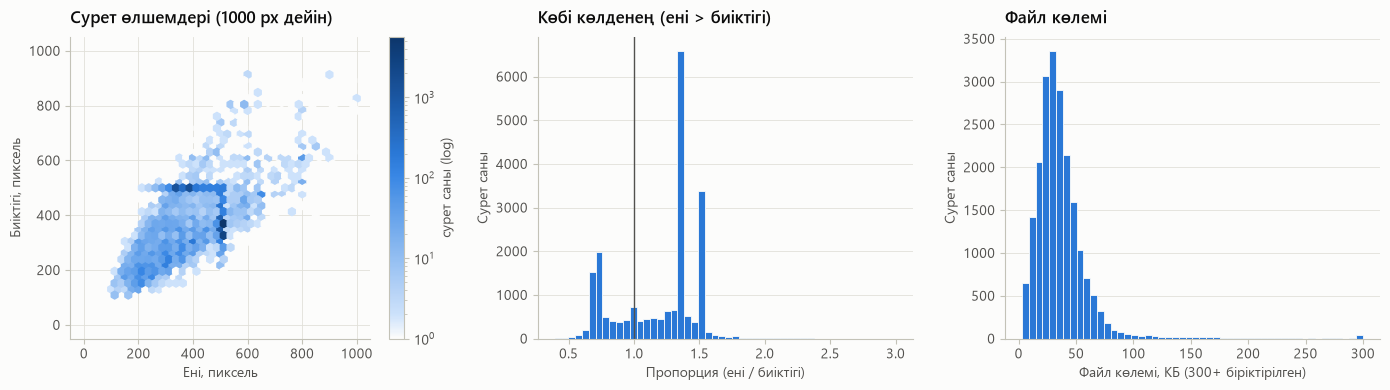

,width,height
min,97.0,100.0
median,500.0,375.0
max,3264.0,2562.0


In [8]:
eda.fig_image_sizes(df, show=True)
df[["width", "height"]].agg(["min", "median", "max"])

**Қорытынды:** суреттердің өлшемі әртүрлі (ені 97–3264, биіктігі 100–2562 пиксель, медианасы 500×375).
Көбі көлденең, 4:3 пропорциялы (медианасы 1,333). Нейрондық желі тұрақты өлшем күтеді, сондықтан барлық сурет модельдің кіріс өлшеміне
(224, 299 немесе 331 пиксель) келтіріледі. Кішкентай суреттер үлкейтіледі, бұл сапасын төмендетуі мүмкін.

## 6. Аннотация: ит кадрдың қанша бөлігін алады?

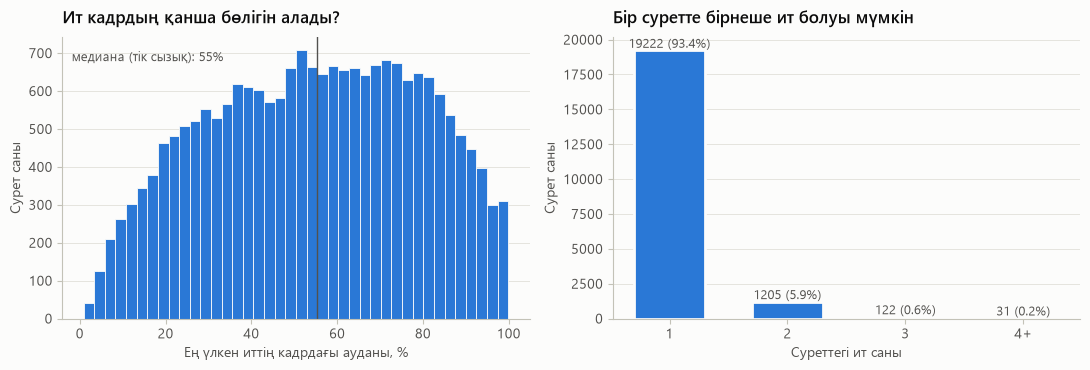

Бірнеше ит бар суреттер үлесі: 0.066
Ит кадрдың 25%-ынан азын алатын суреттер үлесі: 0.1454


In [9]:
eda.fig_bbox(df, show=True)
print("Бірнеше ит бар суреттер үлесі:", round((df["n_dogs"] > 1).mean(), 4))
print("Ит кадрдың 25%-ынан азын алатын суреттер үлесі:", round((df["bbox_frac_max"] < 0.25).mean(), 4))

**Қорытынды:** орташа алғанда ит кадрдың шамамен жартысын алады (медианасы 55%). Бірақ суреттердің **14,5%-ында ит кадрдың 25%-ынан азын** алады,
ал **6,6%-ында бірнеше ит** бар. Мұндай суреттер модельге қиын болуы мүмкін. Бұл болжамды қателерді талдау кезінде тексереміз (`02_Modeling_and_Evaluation.ipynb`).

## 7. Түс және жарықтық

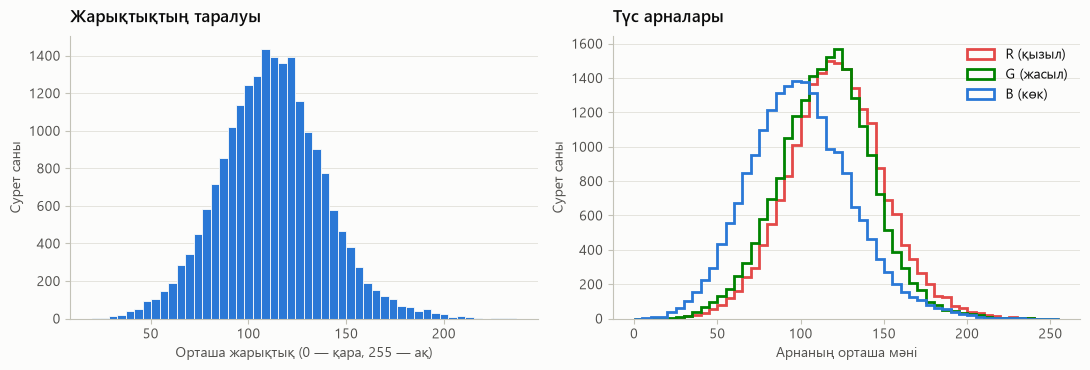

,brightness,mean_r,mean_g,mean_b
count,20580.0,20580.0,20580.0,20580.0
mean,112.1,121.4,115.2,99.7
std,26.8,28.5,27.8,30.7
min,19.7,26.8,10.9,7.6
25%,94.5,102.8,97.0,78.7
50%,111.7,121.0,115.9,98.3
75%,128.8,139.8,133.4,119.3
max,237.0,239.2,237.8,234.2


In [10]:
eda.fig_brightness(df, show=True)
df[["brightness", "mean_r", "mean_g", "mean_b"]].describe().round(1)

**Қорытынды:** суреттердің жарықтығы мен түсі кең ауқымда (қараңғы бөлмелер де, қардағы ақ фон да бар). Алдын ала үйретілген модельдер
мұндай айырмашылыққа төзімді, сондықтан қосымша түс түзетуі қажет емес. Тек әр модельдің өз нормализациясын (`preprocess_input`) қолданамыз.

## 8. Мысалдар

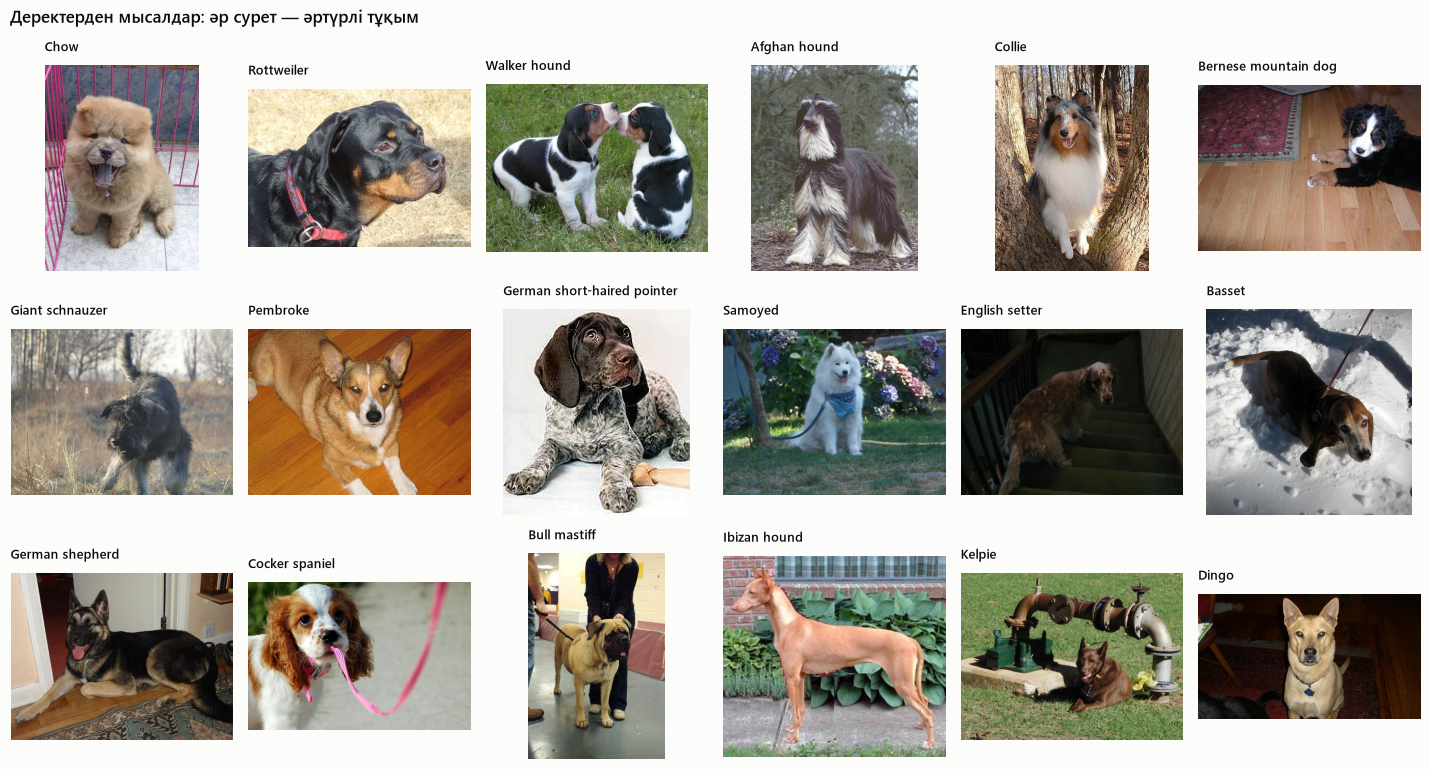

In [11]:
eda.fig_samples(df, show=True)

Мысалдардан көрінетіні: фон, ракурс, жарық әртүрлі. Суретте адамдар немесе басқа заттар бар, ал кейде ит күшік жасында (ересек итке ұқсамайды).
Тұқымдар арасындағы айырма кейде өте аз (*fine-grained* міндет).

## 9. Деректердегі белгі қателері

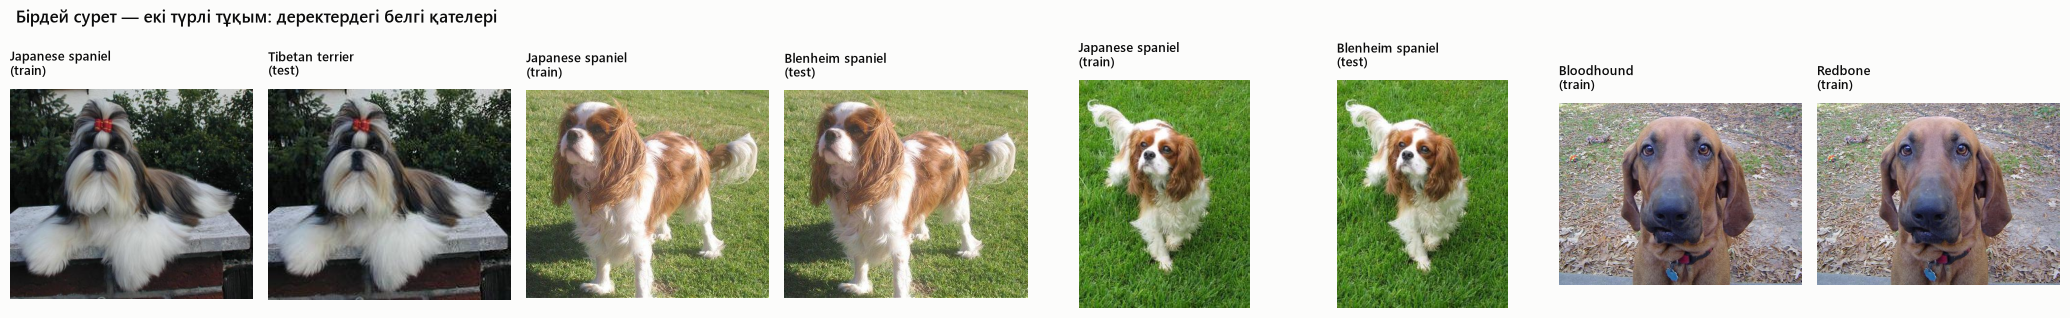

,paths,breeds,splits
0,[n02085782-Japanese_spaniel/n02085782_2459.jpg...,"[Japanese_spaniel, Tibetan_terrier]","[train, test]"
1,"[n02085782-Japanese_spaniel/n02085782_313.jpg,...","[Japanese_spaniel, Blenheim_spaniel]","[train, test]"
2,"[n02085782-Japanese_spaniel/n02085782_186.jpg,...","[Japanese_spaniel, Blenheim_spaniel]","[train, test]"
3,"[n02088466-bloodhound/n02088466_7462.jpg, n020...","[bloodhound, redbone]","[train, train]"


In [12]:
conflicts = eda.fig_duplicates(show=True)
pd.DataFrame(conflicts)

Бұл суреттер **толығымен бірдей**, бірақ әртүрлі тұқыммен белгіленген. Мысалы, Walker hound ↔ English foxhound, Japanese spaniel ↔ Blenheim spaniel ↔ Tibetan terrier.
Яғни деректердің өзінде «шу» бар: test-тегі кейбір «қателерді» модель түбегейлі болдыра алмайды. Бұл модельдің шектеулерін түсіндіруде маңызды.

## 10. EDA қорытындылары және модельге әсері

| Байқау | Модельге әсері |
|---|---|
| 120 класс, 20 580 сурет, тұқымдар өте ұқсас | Нөлден оқыту қиын → **transfer learning** қолданамыз |
| Жетіспейтін мән, бұзылған файл жоқ | Толтыру (imputation) қажет емес |
| 1 файл PNG, 130 көшірме, 48 белгі қайшылығы | Түзетілді / train-нен алынды, **leakage** жойылды |
| train теңестірілген, test теңестірілмеген | Класс салмақтары қажет емес, бірақ **macro F1** есептейміз |
| Өлшемдер әртүрлі | Барлық сурет модельдің кіріс өлшеміне келтіріледі |
| 14,5% суретте ит кішкентай, 6,6%-ында бірнеше ит | Қателерді талдауда тексереміз |
| Суреттер ImageNet-тен алынған | Шектеу: ImageNet-те үйретілген модельдер бұл суреттерді «көруі» мүмкін |

In [13]:
stats = eda.basic_stats(df)
stats

{'n_images_total': 20580,
 'n_images_used': 20450,
 'n_classes': 120,
 'missing_values': 0,
 'formats': {'JPEG': 20579, 'PNG': 1},
 'modes': {'RGB': 20579, 'RGBA': 1},
 'median_width': 500,
 'median_height': 375,
 'min_width': 97,
 'max_width': 3264,
 'min_height': 100,
 'max_height': 2562,
 'median_aspect': 1.333,
 'median_file_kb': 32.2,
 'per_class_min': {'breed': 'Dhole', 'n': 144},
 'per_class_max': {'breed': 'Maltese dog', 'n': 252},
 'train_per_class_min': 77,
 'train_per_class_max': 85,
 'test_per_class_min': 48,
 'test_per_class_max': 152,
 'share_multi_dog': 0.066,
 'median_bbox_frac': 0.553,
 'share_dog_lt_25pct': 0.1454,
 'median_brightness': 111.7}